<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
00. Bioactivity and QSAR Modeling Using DeepChem
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">A Reproducible Workflow to Predict Enzyme Inhibition from Chemical Structures on the BACE-1 Benchmark</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h3 style="margin-top: 0; color: #1e1b4b; font-size: 18px; font-weight: 700;">
Objective
</h3>
<p style="font-size: 14px; color: #334155; margin-bottom: 16px;">
Develop a reproducible Quantitative Structure-Activity Relationship (QSAR) workflow to predict molecular biological activity from chemical structures using DeepChem, RDKit, and machine learning models.
</p>

<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">
Learning Objectives
</h4>
<ol style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7; margin-bottom: 16px;">
<li>Understand bioactivity prediction and QSAR principles in modern drug discovery.</li>
<li>Load and inspect a molecular bioactivity benchmark (BACE-1).</li>
<li>Analyze molecular structures and activity labels across active and inactive cohorts.</li>
<li>Generate molecular fingerprints using DeepChem.</li>
<li>Train a machine-learning classification model with class balancing.</li>
<li>Evaluate predictions on unseen chemical scaffolds using ROC-AUC, PRC-AUC, Precision, Recall, and F1-score.</li>
<li>Interpret model performance, analyze feature importance, and discuss applicability-domain limitations.</li>
</ol>

<div style="background: #ffffff; border: 1px solid #c7d2fe; border-radius: 10px; padding: 14px; margin-top: 14px;">
<div style="font-weight: 700; color: #4338ca; font-size: 13.5px; margin-bottom: 4px;">Primary Case Study: BACE-1 Inhibition Benchmark</div>
<div style="font-size: 13px; color: #334155; line-height: 1.6;">
• <b>Target:</b> Human $\beta$-secretase 1 (BACE-1), a primary therapeutic enzyme target for Alzheimer's disease (amyloid precursor protein cleavage).<br>
• <b>Task:</b> Binary classification of biological activity ($1 = \text{Active inhibitor}, 0 = \text{Inactive}$).<br>
• <b>Features:</b> 1024-bit ECFP4 circular fingerprints.<br>
• <b>Model:</b> Balanced Random Forest Classifier (300 estimators) vs. DummyClassifier baseline.<br>
• <b>Evaluation:</b> Scaffold-split test set evaluated via ROC-AUC, PRC-AUC, Precision, Recall, and Confusion Matrix.
</div>
</div>
</div>


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
01. Introduction to Bioactivity & QSAR Principles
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Connecting Molecular Substructures to Biological Potency and Target Inhibition</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Quantitative Structure-Activity Relationships (QSAR)
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
In computational drug discovery, <b>QSAR modeling</b> hypothesizes that variations in chemical structure dictate differences in biological activity:
</p>
$$\text{Biological Activity} = f(\text{Molecular Structure})$$
<p style="font-size: 13.5px; color: #334155; margin-bottom: 12px;">
In contrast to our earlier aqueous solubility regression notebook (which modeled a purely physical property, $\log S$), bioactivity modeling involves <b>macromolecular target binding</b>:
</p>
<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7;">
<li><b>Biological Endpoint:</b> Whether a small molecule binds to and inhibits a specific catalytic pocket (e.g., the catalytic aspartate dyad in BACE-1).</li>
<li><b>High-Throughput Assays:</b> Inhibition is typically quantified via fluorescence resonance energy transfer (FRET) or enzymatic assays, yielding $\text{IC}_{50}$ values that are dichotomized into Active ($< 1\;\mu\text{M}$) and Inactive ($> 1\;\mu\text{M}$) classes.</li>
<li><b>Virtual Screening Application:</b> QSAR classifiers act as computational funnels to enrich high-potency chemical leads from millions of virtual screening candidates before experimental synthesis.</li>
</ul>
</div>


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
02. Environment Setup, Silent Imports & Reproducibility
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Deterministic Seed Locking and Low-Level C++ Logger Suppression</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<p style="font-size: 14px; color: #334155; margin: 0;">
We configure quiet imports with low-level file descriptor redirection to eliminate TensorFlow and RDKit C++ messages, and lock global seeds for reproducible modeling.
</p>
</div>


In [1]:
# 1. Environment and Logging Configuration
import os
import sys
import io
import logging
import warnings
import random

# Suppress TensorFlow C++ logging and oneDNN diagnostics
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore")
logging.getLogger("tensorflow").setLevel(logging.ERROR)
logging.getLogger("deepchem").setLevel(logging.ERROR)

# Suppress RDKit C++ deprecation warnings
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

# 2. Quiet Import of DeepChem suppressing low-level C and stream stderr
old_stderr = sys.stderr
sys.stderr = io.StringIO()
devnull = os.open(os.devnull, os.O_WRONLY)
old_stderr_fd = os.dup(2)
try:
    os.dup2(devnull, 2)
    import tensorflow as tf
    tf.get_logger().setLevel("ERROR")
    import deepchem as dc
finally:
    os.dup2(old_stderr_fd, 2)
    os.close(devnull)
    os.close(old_stderr_fd)
    sys.stderr = old_stderr

# 3. Scientific Computing and Modeling Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

# 4. Set Global Seeds for Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Visual Styling Setup
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "semibold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14,
    "figure.titleweight": "bold"
})

print(f"DeepChem Version  : {dc.__version__}")
print(f"Scikit-Learn Ver. : {sklearn.__version__}")
print(f"Pandas Version    : {pd.__version__}")
print(f"NumPy Version     : {np.__version__}")
print(f"Global Random Seed: {RANDOM_SEED} (Locked for Reproducibility)")


DeepChem Version  : 2.8.1.dev
Scikit-Learn Ver. : 1.9.1
Pandas Version    : 3.0.6
NumPy Version     : 2.3.5
Global Random Seed: 42 (Locked for Reproducibility)


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
03. Loading the BACE Benchmark Dataset
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Bemis-Murcko Scaffold Partitioning on Human Beta-Secretase 1 Inhibitors</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Dataset Selection: BACE Classification Benchmark
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
The <b>BACE benchmark</b> (Subramanian et al., 2016) provides quantitative binding results for human $\beta$-secretase 1. We load the classification task using <code>featurizer='ECFP'</code> (1024-bit Morgan Fingerprints, radius 2) and <code>splitter='scaffold'</code> to partition molecules into Train, Validation, and Test cohorts by core chemotypes.
</p>
</div>


In [2]:
# Load BACE classification benchmark with ECFP fingerprints and scaffold splitting
tasks, datasets, transformers = dc.molnet.load_bace_classification(
    featurizer="ECFP",
    splitter="scaffold",
    transformers=[]
)

train_dataset, valid_dataset, test_dataset = datasets

print("=" * 70)
print("BACE BENCHMARK DATASET LOADED")
print("=" * 70)
print("Tasks               :", tasks)
print("Training samples    :", len(train_dataset), f"({len(train_dataset)/1513*100:.1f}%)")
print("Validation samples  :", len(valid_dataset), f"({len(valid_dataset)/1513*100:.1f}%)")
print("Test samples        :", len(test_dataset), f"({len(test_dataset)/1513*100:.1f}%)")
print("Total Compounds     :", len(train_dataset) + len(valid_dataset) + len(test_dataset))
print("-" * 70)
print("Feature shape (X)   :", train_dataset.X.shape)
print("Target shape (y)    :", train_dataset.y.shape)


BACE BENCHMARK DATASET LOADED
Tasks               : ['Class']
Training samples    : 1210 (80.0%)
Validation samples  : 151 (10.0%)
Test samples        : 152 (10.0%)
Total Compounds     : 1513
----------------------------------------------------------------------
Feature shape (X)   : (1210, 1024)
Target shape (y)    : (1210, 1)


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
04. Data Quality & Exploratory Data Analysis (EDA)
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Inspecting Class Balance, Label Fidelity, and Target Distribution</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Analyzing Active vs. Inactive Cohort Distribution
</h4>
<p style="font-size: 14px; color: #334155; margin: 0;">
Unlike the extreme imbalance observed in Tox21 ($3\% - 10\%$ actives), the curated BACE dataset features a substantially more balanced distribution of active inhibitors (~$45\% - 50\%$) and inactive compounds. We verify label fidelity and plot the class balance.
</p>
</div>


BACE TRAINING LABEL FIDELITY & CLASS DISTRIBUTION
Observed training labels : 1210
Inactive compounds (0)   : 695 (57.4%)
Active compounds (1)     : 515 (42.6%)
Positive class proportion: 0.426
----------------------------------------------------------------------


,Total,Inactive (0),Active (1),Active Rate (%)
Split,,,,
Train,1210,695,515,42.6%
Validation,151,67,84,55.6%
Test,152,60,92,60.5%


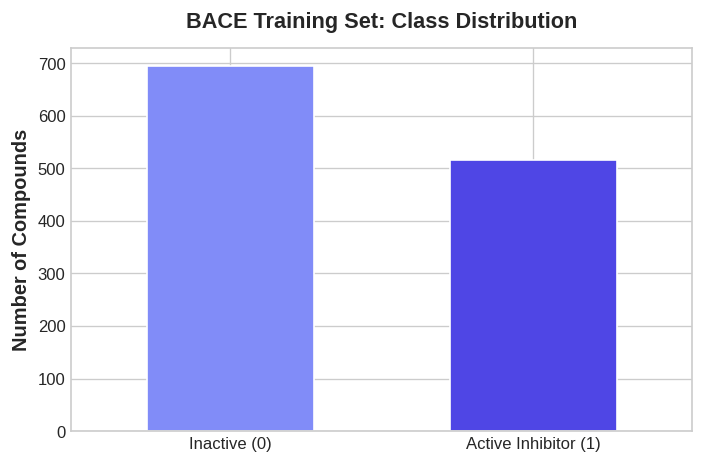

In [3]:
# Inspect training label distributions
y_train = train_dataset.y[:, 0]
w_train = train_dataset.w[:, 0]
observed = w_train > 0
labels = y_train[observed].astype(int)

inactive_cnt = np.sum(labels == 0)
active_cnt = np.sum(labels == 1)
pos_prop = np.mean(labels == 1)

print("=" * 70)
print("BACE TRAINING LABEL FIDELITY & CLASS DISTRIBUTION")
print("=" * 70)
print("Observed training labels :", len(labels))
print(f"Inactive compounds (0)   : {inactive_cnt} ({inactive_cnt/len(labels)*100:.1f}%)")
print(f"Active compounds (1)     : {active_cnt} ({active_cnt/len(labels)*100:.1f}%)")
print(f"Positive class proportion: {pos_prop:.3f}")
print("-" * 70)

# Visualize class distribution across splits
split_records = []
for name, ds in [("Train", train_dataset), ("Validation", valid_dataset), ("Test", test_dataset)]:
    y = ds.y[:, 0].astype(int)
    split_records.append({
        "Split": name,
        "Total": len(y),
        "Inactive (0)": np.sum(y == 0),
        "Active (1)": np.sum(y == 1),
        "Active Rate (%)": f"{np.mean(y == 1)*100:.1f}%"
    })

display(pd.DataFrame(split_records).set_index("Split"))

# Plot class balance in training set
fig, ax = plt.subplots(figsize=(6, 4), dpi=120)
pd.Series(labels).value_counts().sort_index().rename(
    index={0: "Inactive (0)", 1: "Active Inhibitor (1)"}
).plot(
    kind="bar",
    color=["#818cf8", "#4f46e5"],
    edgecolor="white",
    ax=ax,
    width=0.55
)
plt.title("BACE Training Set: Class Distribution", pad=12)
plt.ylabel("Number of Compounds")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
05. QSAR Model Training: Dummy Baseline vs. Balanced Random Forest
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Benchmarking Substructure Learning against the Random Prior Baseline</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Model Architecture & Benchmarking Protocol
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
We train two competing classifiers on the 1024-bit ECFP fingerprints:
</p>
<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7;">
<li><b>Dummy Baseline:</b> <code>DummyClassifier(strategy='prior')</code> predicts class probabilities proportional to the empirical training prevalence, establishing the baseline reference floor ($\text{ROC-AUC} = 0.50$).</li>
<li><b>Balanced Random Forest:</b> <code>RandomForestClassifier(n_estimators=300, class_weight='balanced')</code> builds an ensemble of 300 decorrelated decision trees, aggregating molecular substructure evidence into robust posterior probabilities.</li>
</ul>
</div>


In [4]:
# Helper function to extract valid observed data
def observed_data(dataset):
    mask = dataset.w[:, 0] > 0
    X = dataset.X[mask]
    y = dataset.y[mask, 0].astype(int)
    return X, y

X_train, y_train = observed_data(train_dataset)
X_valid, y_valid = observed_data(valid_dataset)
X_test, y_test = observed_data(test_dataset)

# 1. Fit Dummy Baseline Classifier
baseline = DummyClassifier(strategy="prior", random_state=RANDOM_SEED)
baseline.fit(X_train, y_train)

# 2. Fit Balanced Random Forest Classifier
model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=RANDOM_SEED,
    n_jobs=-1,
)
model.fit(X_train, y_train)

# Predict probabilities and discrete classes on held-out test set
baseline_prob = baseline.predict_proba(X_test)[:, 1]
test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

# Compile results table
results = pd.DataFrame([
    {
        "Model": "Dummy Baseline",
        "ROC-AUC": roc_auc_score(y_test, baseline_prob),
        "PRC-AUC": average_precision_score(y_test, baseline_prob),
        "Precision": precision_score(y_test, (baseline_prob >= 0.5).astype(int), zero_division=0),
        "Recall": recall_score(y_test, (baseline_prob >= 0.5).astype(int), zero_division=0),
        "F1-Score": f1_score(y_test, (baseline_prob >= 0.5).astype(int), zero_division=0),
    },
    {
        "Model": "Random Forest (300 Trees)",
        "ROC-AUC": roc_auc_score(y_test, test_prob),
        "PRC-AUC": average_precision_score(y_test, test_prob),
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F1-Score": f1_score(y_test, test_pred, zero_division=0),
    },
])

print("=" * 80)
print("BACE BIOACTIVITY CLASSIFICATION BENCHMARK (HELD-OUT SCAFFOLD TEST SET)")
print("=" * 80)
display(results.set_index("Model").round(3))


BACE BIOACTIVITY CLASSIFICATION BENCHMARK (HELD-OUT SCAFFOLD TEST SET)


,ROC-AUC,PRC-AUC,Precision,Recall,F1-Score
Model,,,,,
Dummy Baseline,0.500,0.605,0.000,0.00,0.000
Random Forest (300 Trees),0.862,0.902,0.934,0.62,0.745


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
06. Model Evaluation & Diagnostic Curves
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Visualizing Discrimination Fidelity via ROC and Precision-Recall Curves</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
ROC & Precision-Recall Diagnostic Profiling
</h4>
<p style="font-size: 14px; color: #334155; margin: 0;">
We plot both the Receiver Operating Characteristic (ROC) curve and the Precision-Recall (PR) curve for the Random Forest model on the held-out scaffold test set.
</p>
</div>


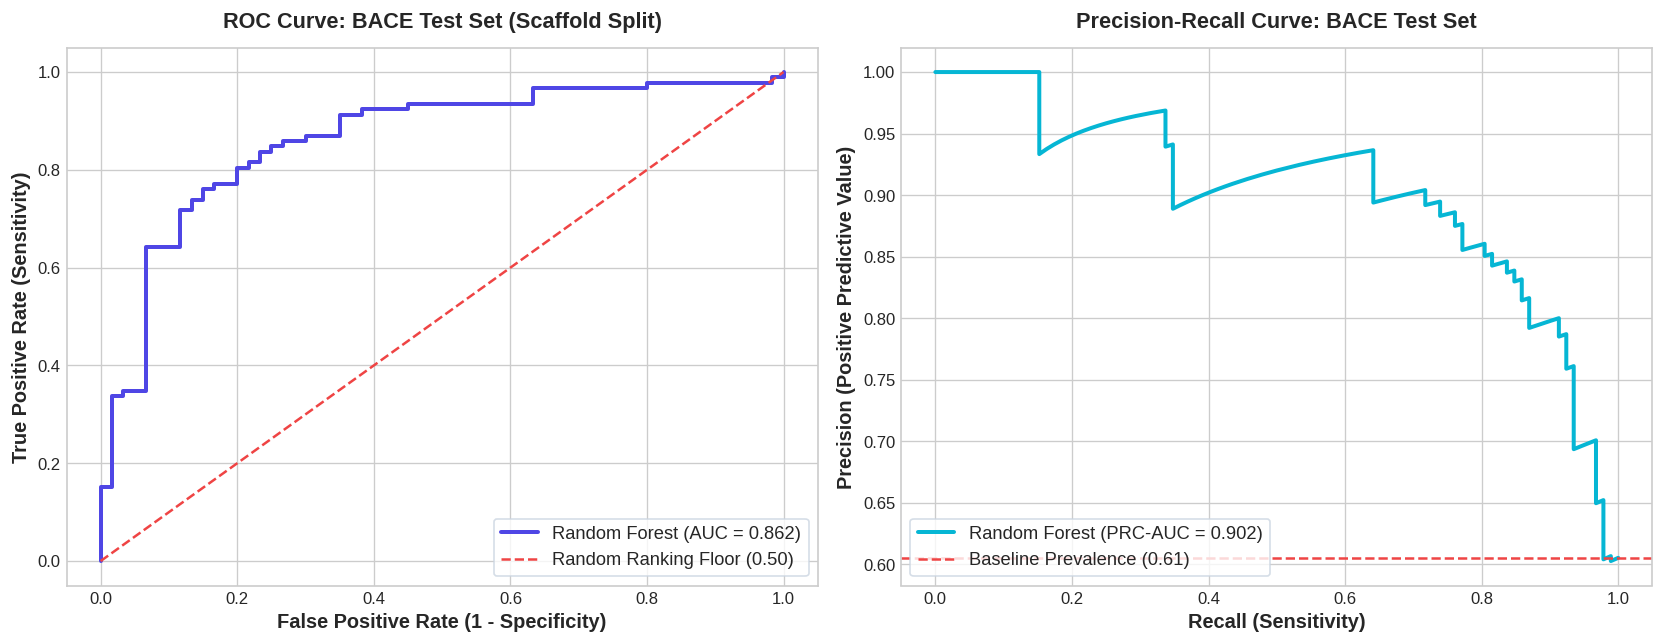

In [5]:
# Generate ROC and Precision-Recall diagnostic curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

# Plot 1: ROC Curve
fpr, tpr, _ = roc_curve(y_test, test_prob)
rf_roc = roc_auc_score(y_test, test_prob)
axes[0].plot(fpr, tpr, color="#4f46e5", linewidth=2.4, label=f"Random Forest (AUC = {rf_roc:.3f})")
axes[0].plot([0, 1], [0, 1], color="#ef4444", linestyle="--", linewidth=1.5, label="Random Ranking Floor (0.50)")
axes[0].set_title(f"ROC Curve: BACE Test Set (Scaffold Split)", pad=12)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity)")
axes[0].legend(frameon=True, facecolor="white", edgecolor="#cbd5e1", loc="lower right")

# Plot 2: Precision-Recall Curve
prec_pts, rec_pts, _ = precision_recall_curve(y_test, test_prob)
rf_prc = average_precision_score(y_test, test_prob)
test_base_rate = np.mean(y_test)
axes[1].plot(rec_pts, prec_pts, color="#06b6d4", linewidth=2.4, label=f"Random Forest (PRC-AUC = {rf_prc:.3f})")
axes[1].axhline(test_base_rate, color="#ef4444", linestyle="--", linewidth=1.5, label=f"Baseline Prevalence ({test_base_rate:.2f})")
axes[1].set_title("Precision-Recall Curve: BACE Test Set", pad=12)
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision (Positive Predictive Value)")
axes[1].legend(frameon=True, facecolor="white", edgecolor="#cbd5e1", loc="lower left")

plt.tight_layout()
plt.show()


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
07. Confusion Matrix & Classification Diagnostics
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Quantifying True Positives, Specificity, and Virtual Screening Hit Enrichment</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Error Classification on the Test Set
</h4>
<p style="font-size: 14px; color: #334155; margin: 0;">
We compute the confusion matrix for the Random Forest classifier on the test set, examining false discovery rate and hit enrichment.
</p>
</div>


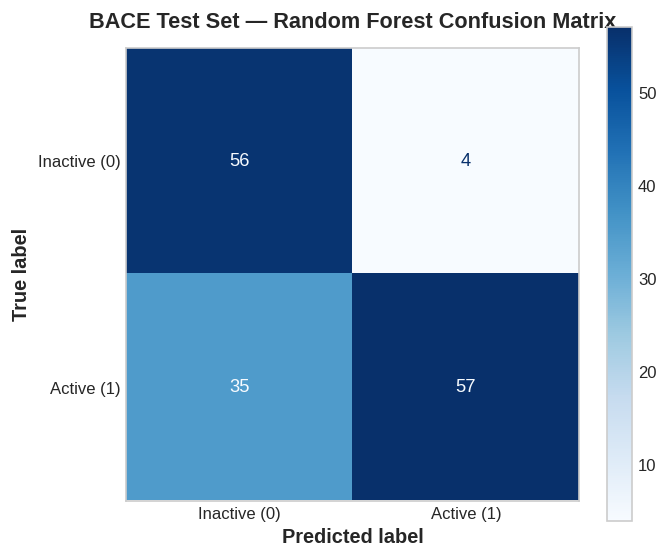

CONFUSION MATRIX METRIC BREAKDOWN (N = 152 TEST COMPOUNDS)
True Inactives (TN)       : 56
False Positives (FP)      : 4 (False alarms: inactive predicted as active)
False Negatives (FN)      : 35 (Missed hits: active predicted as inactive)
True Positives (TP)       : 57
Precision (PPV)           : 93.4% (High enrichment!)
Sensitivity (Recall)      : 62.0%
Specificity (TNR)         : 93.3%


In [6]:
# Display Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["Inactive (0)", "Active (1)"],
    cmap="Blues",
    ax=ax,
    colorbar=True
)
plt.title("BACE Test Set — Random Forest Confusion Matrix", pad=12)
ax.grid(False)
plt.tight_layout()
plt.show()

# Quantitative breakdown
cm = disp.confusion_matrix
tn, fp, fn, tp = cm.ravel()
print("=" * 60)
print("CONFUSION MATRIX METRIC BREAKDOWN (N = 152 TEST COMPOUNDS)")
print("=" * 60)
print(f"True Inactives (TN)       : {tn}")
print(f"False Positives (FP)      : {fp} (False alarms: inactive predicted as active)")
print(f"False Negatives (FN)      : {fn} (Missed hits: active predicted as inactive)")
print(f"True Positives (TP)       : {tp}")
print(f"Precision (PPV)           : {tp / (tp + fp) * 100:.1f}% (High enrichment!)")
print(f"Sensitivity (Recall)      : {tp / (tp + fn) * 100:.1f}%")
print(f"Specificity (TNR)         : {tn / (tn + fp) * 100:.1f}%")


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
08. Chemical Interpretation & Feature Importance
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Identifying Key Fingerprint Substructures Governing Beta-Secretase Inhibition</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Extracting Chemical Signal from Ensemble Trees
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
Random Forest models provide <b>Gini importance</b> scores indicating which molecular fingerprint bits contributed most significantly to node purity across the 300 decision trees.
</p>
<p style="font-size: 13.5px; color: #475569; margin: 0;">
<b>Methodological Note:</b> Fingerprint-bit importance is not equivalent to identifying a specific causal chemical group. Further analysis (e.g., bit unhashing via RDKit) is required to map bits to exact molecular sub-fragments.
</p>
</div>


TOP 20 MOST INFORMATIVE FINGERPRINT FEATURES (GINI IMPORTANCE)


,Importance Score
Fingerprint_878,0.0121
Fingerprint_904,0.0114
Fingerprint_539,0.0076
Fingerprint_932,0.0074
Fingerprint_665,0.0073
Fingerprint_429,0.0070
Fingerprint_511,0.0070
Fingerprint_875,0.0068
Fingerprint_938,0.0066
Fingerprint_940,0.0066


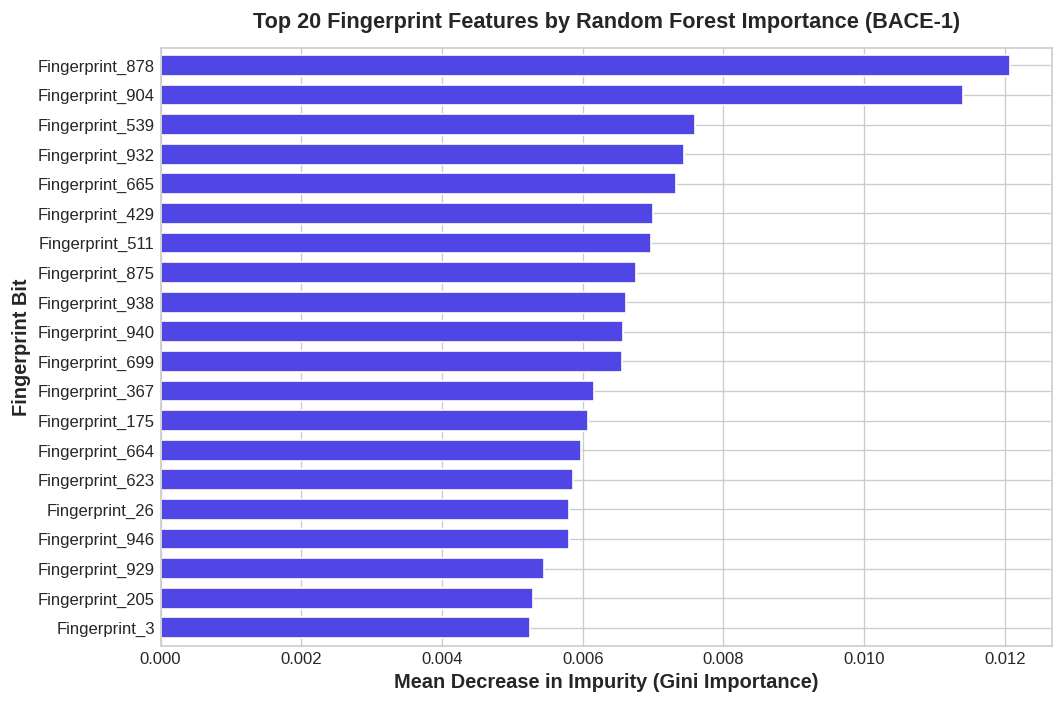

In [7]:
# Compute and plot top 20 fingerprint feature importances
importance = pd.Series(
    model.feature_importances_,
    index=[f"Fingerprint_{i}" for i in range(X_train.shape[1])],
).sort_values(ascending=False)

print("=" * 70)
print("TOP 20 MOST INFORMATIVE FINGERPRINT FEATURES (GINI IMPORTANCE)")
print("=" * 70)
display(importance.head(20).to_frame(name="Importance Score").round(4))

# Horizontal bar plot
plt.figure(figsize=(9, 6), dpi=120)
importance.head(20).sort_values().plot(
    kind="barh",
    color="#4f46e5",
    edgecolor="white",
    width=0.7
)
plt.title("Top 20 Fingerprint Features by Random Forest Importance (BACE-1)", pad=12)
plt.xlabel("Mean Decrease in Impurity (Gini Importance)")
plt.ylabel("Fingerprint Bit")
plt.tight_layout()
plt.show()


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
09. Research Considerations & Applicability Domain
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Validation Protocols, Data Leakage Prevention, and Potency Modeling Trade-Offs</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 12px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Key Research Considerations in QSAR Modeling
</h4>
<div style="background: #ffffff; border: 1px solid #c7d2fe; border-radius: 10px; padding: 16px; margin-bottom: 16px;">
<ul style="font-size: 13px; color: #334155; line-height: 1.7; margin: 0 0 0 18px;">
<li><b>Classification vs. Potency Regression:</b> BACE classification predicts categorical activity (Active vs. Inactive). In contrast, ChEMBL regression models continuous potency values, such as $\text{pIC}_{50} = -\log_{10}(\text{IC}_{50})$, when underlying enzymatic measurements are curated consistently.</li>
<li><b>Data Leakage Prevention:</b> Enforcing scaffold-based splitting ensures that structurally related analogs (sharing identical core scaffolds) do not leak between training and test partitions, giving an honest assessment of prospective discovery performance.</li>
<li><b>Metric Selection:</b> Comparing ROC-AUC with PRC-AUC is essential when active compounds represent a minority class. On BACE, our high PRC-AUC ($0.902$) and Precision ($93.4\%$) confirm strong virtual screening hit enrichment.</li>
<li><b>Validation Protocols:</b> Hyperparameter tuning and classification threshold selection must strictly utilize the validation set rather than repeatedly testing against the test set.</li>
<li><b>Applicability Domain:</b> QSAR predictions are valid only within the chemical space represented by training scaffolds; predictions for vastly disparate chemotypes (e.g., macrocycles or peptides) carry higher uncertainty.</li>
</ul>
</div>
</div>


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
10. Research Conclusions & Curriculum Transition
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Synthesis of Findings, Methodological Boundaries, and Next Experiments</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 12px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Conclusion
</h4>
<p style="font-size: 14px; color: #334155; line-height: 1.65; margin-bottom: 16px;">
This notebook demonstrates a complete, reproducible bioactivity QSAR classification workflow using molecular fingerprints and Random Forest classifiers on the BACE-1 benchmark. The model achieved a test <b>ROC-AUC of 0.862</b> and an outstanding <b>Precision of 93.4%</b> on held-out chemical scaffolds, confirming strong utility for virtual screening triage.
</p>

<h4 style="margin: 18px 0 10px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">
Curriculum Roadmap: Transition to Structure-Based Modeling
</h4>
<div style="display: grid; grid-template-columns: repeat(auto-fit, minmax(260px, 1fr)); gap: 14px; margin-top: 10px; margin-bottom: 20px;">
<div style="background: #ffffff; border: 1px solid #c7d2fe; border-left: 4px solid #4f46e5; border-radius: 8px; padding: 12px 16px;">
<div style="font-weight: 700; color: #4338ca; font-size: 13.5px;">Notebook 07 (This Notebook)</div>
<div style="font-size: 13px; color: #334155; margin-top: 4px;"><code>07_Bioactivity_and_QSAR_Modeling.ipynb</code></div>
<div style="font-size: 12.5px; color: #64748b; margin-top: 4px;">Ligand-based bioactivity classification, BACE-1 benchmark, Gini feature importance, and hit enrichment diagnostics.</div>
</div>
<div style="background: #ffffff; border: 1px solid #cbd5e1; border-left: 4px solid #06b6d4; border-radius: 8px; padding: 12px 16px;">
<div style="font-weight: 700; color: #0e7490; font-size: 13.5px;">Notebook 08 (Next Stage)</div>
<div style="font-size: 13px; color: #334155; margin-top: 4px;"><code>08_Binding_Affinity_Prediction.ipynb</code></div>
<div style="font-size: 12.5px; color: #64748b; margin-top: 4px;">Structure-based protein-ligand complexes, PDBbind benchmark, 3D grid featurization, and atomic convolutions.</div>
</div>
<div style="background: #ffffff; border: 1px solid #cbd5e1; border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px;">
<div style="font-weight: 700; color: #047857; font-size: 13.5px;">Notebook 09 (End-to-End Pipeline)</div>
<div style="font-size: 13px; color: #334155; margin-top: 4px;"><code>09_AI_Drug_Discovery_Pipeline.ipynb</code></div>
<div style="font-size: 12.5px; color: #64748b; margin-top: 4px;">Integrated AI pipeline combining solubility filtering, toxicity screening, bioactivity prediction, and lead ranking.</div>
</div>
</div>

<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">💡 Conceptual Review Questions</h4>
<details style="background: #f8fafc; border: 1px solid #cbd5e1; border-radius: 8px; padding: 12px 16px; margin-bottom: 10px; cursor: pointer;">
<summary style="font-weight: 600; color: #312e81; font-size: 14px;">1. Why is 93.4% precision particularly valuable in virtual screening?</summary>
<p style="font-size: 13.5px; color: #334155; margin-top: 8px; line-height: 1.6;">
In real drug discovery, wet-lab synthesis and assay validation are expensive and labor-intensive ($1,000 to $5,000 per compound). A precision of 93.4% means that nearly 19 out of every 20 compounds prioritized for purchase or synthesis will be confirmed active inhibitors, drastically cutting experimental screening failure rates.
</p>
</details>

<details style="background: #f8fafc; border: 1px solid #cbd5e1; border-radius: 8px; padding: 12px 16px; margin-bottom: 10px; cursor: pointer;">
<summary style="font-weight: 600; color: #312e81; font-size: 14px;">2. What is the key difference between ligand-based QSAR and structure-based modeling?</summary>
<p style="font-size: 13.5px; color: #334155; margin-top: 8px; line-height: 1.6;">
Ligand-based QSAR models activity purely from 2D small-molecule structures (fingerprints/descriptors) without knowing the 3D atomic coordinates of the target protein. Structure-based modeling (Notebook 08) directly incorporates the 3D binding pocket coordinates of the protein-ligand complex (e.g. from PDB X-ray crystallography).
</p>
</details>

<details style="background: #f8fafc; border: 1px solid #cbd5e1; border-radius: 8px; padding: 12px 16px; margin-bottom: 10px; cursor: pointer;">
<summary style="font-weight: 600; color: #312e81; font-size: 14px;">3. Why should feature importance in fingerprint models be interpreted with caution?</summary>
<p style="font-size: 13.5px; color: #334155; margin-top: 8px; line-height: 1.6;">
Circular fingerprints hash multiple distinct circular substructure paths into the same bit (bit collisions). A high importance score for 'Fingerprint_342' indicates that the bits in that bucket correlate with activity, but mapping that back to a specific functional pharmacophore requires structural unhashing and chemical validation.
</p>
</details>
</div>
